# 05 — Neural networks

This notebook fits two neural models on the same Phase 4 partitions. The multilayer perceptron is an approved experiment. It reads the training-only one-hot pipeline, outputs three logits, and minimises class-weighted cross-entropy. Early stopping restores the epoch with the highest validation macro-F1.

The second architecture is a categorical embedding network. It is a prepared option for a task with high-cardinality categories. Lecturer approval was recorded later, without an approval date and without a change to this architecture. The outputs saved in this notebook are the original run. The champion rule is validation macro-F1, and these scores do not replace histogram gradient boosting.

The locked test is not scored. The champion is the approved model with the highest validation macro-F1.


## 1. Setup and the shared partitions


In [1]:
from pathlib import Path
import sys

import numpy as np
import pandas as pd
from IPython.display import Image, display

cwd = Path.cwd().resolve()
project_root = None
for candidate in [cwd, *cwd.parents]:
    if (candidate / "src" / "config.py").is_file():
        project_root = candidate
        break
if project_root is None:
    raise FileNotFoundError("Start JupyterLab from the project folder.")
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from src import config
from src.evaluation import classification_scores
from src.neural import APPROVED_EMBEDDING_NOTE, predict_embedding, predict_feedforward, train_embedding_network, train_feedforward
from src.preprocessing import (
    SOURCE_CATEGORICAL_COLUMNS,
    build_baseline_preprocessor,
    chronological_splits,
    logging_feature_frame,
)
from src.training import (
    APPROVED_APPROVAL,
    EmbeddingCategoryEncoder,
    assert_split_may_be_scored,
    base_experiment_config,
    class_indices,
    render_phase5_report,
    save_json,
    summarise_predictions,
    validation_comparison,
    provisional_champion,
)
from src.visualization import (
    plot_confusion_matrix,
    plot_learning_curves,
    plot_train_validation_macro_f1,
    plot_validation_comparison,
)

config.set_random_seeds()
assert_split_may_be_scored("validation")
traditional_path = config.TABLES_DIR / "05_traditional_summary.csv"
traditional_class_path = config.TABLES_DIR / "05_traditional_per_class.csv"
traditional_run_path = config.TABLES_DIR / "05_traditional_run.json"
for required in (traditional_path, traditional_class_path, traditional_run_path):
    if not required.is_file():
        raise FileNotFoundError(
            "Notebook 05 reads the tables written by notebook 04. "
            f"Missing file: {required}."
        )
print(APPROVED_EMBEDDING_NOTE)
print(f"Project root: {config.PROJECT_ROOT}")
print(f"Random seed: {config.RANDOM_SEED}")


Lecturer approval has been recorded for the existing embedding network. No approval date was supplied, and the architecture was not changed.
Project root: /workspace
Random seed: 42


In [2]:
import json

source_columns = list(SOURCE_CATEGORICAL_COLUMNS) + ["Created_On_Date", "resolution_outcome"]
frame = pd.read_parquet(
    config.PROCESSED_DATA_DIR / "service_requests_labelled.parquet",
    columns=source_columns,
)
splits, split_summary, _exclusions = chronological_splits(frame)
del frame
del splits["test"]
X_train = logging_feature_frame(splits["train"])
X_validation = logging_feature_frame(splits["validation"])
y_train = splits["train"]["resolution_outcome"].to_numpy()
y_validation = splits["validation"]["resolution_outcome"].to_numpy()
del splits

saved_split = pd.read_csv(config.TABLES_DIR / "05_split_summary.csv")
merged = split_summary.merge(saved_split, on="split", suffixes=("_now", "_notebook04"))
if not np.allclose(merged["rows_now"], merged["rows_notebook04"]):
    raise RuntimeError("The row counts do not match the partitions saved by notebook 04.")
print("Training, validation, and locked-test row counts match notebook 04.")
display(split_summary)


Training, validation, and locked-test row counts match notebook 04.


,split,rows,start_date,end_date,Resolved Fast,Resolved Slow,Unresolved,Resolved Fast percent,Resolved Slow percent,Unresolved percent
0,train,2616595,2023-01-01,2024-12-31,1730948,767337,118310,66.152691,29.325784,4.521525
1,validation,936469,2025-02-01,2025-12-31,648570,88411,199488,69.256964,9.440889,21.302147
2,test,422033,2026-01-01,2026-04-30,287131,65522,69380,68.035201,15.525326,16.439473


## 2. Multilayer perceptron

The network is 1,718 one-hot inputs, then two ReLU hidden layers of 128 and 64 units, dropout 0.3, and three logits. The optimiser is AdamW with learning rate 0.001 and weight decay 0.0001. The batch size is 8,192. The loss is cross-entropy with the training balanced class weights. The maximum is 8 epochs, and training stops after 3 epochs without a new best validation macro-F1.

These values were set before the run. They were not selected by a search over the validation score, and the locked test was not consulted. Dropout is on while the weights are updated. The curves below are computed afterwards with dropout off, on the full training and validation periods.


MLP input columns: 1,718


mlp epoch 1: train_loss 0.6380, val_loss 1.4613, train_macro_f1 0.5834, val_macro_f1 0.4748


mlp epoch 2: train_loss 0.6042, val_loss 1.6222, train_macro_f1 0.6137, val_macro_f1 0.4762


mlp epoch 3: train_loss 0.5835, val_loss 1.7432, train_macro_f1 0.6326, val_macro_f1 0.4765


mlp epoch 4: train_loss 0.5711, val_loss 1.8221, train_macro_f1 0.6297, val_macro_f1 0.4727


mlp epoch 5: train_loss 0.5612, val_loss 1.9026, train_macro_f1 0.6358, val_macro_f1 0.4748


mlp epoch 6: train_loss 0.5526, val_loss 1.9927, train_macro_f1 0.6423, val_macro_f1 0.4745


Parameters: 228,483
Epochs run: 6
Restored epoch: 3
Stopped early: True
Fit seconds: 339.6
Class weights: [0.504, 1.137, 7.372]
Architecture, optimiser, learning rate, batch size, dropout, and weight decay:


hidden_sizes            [128, 64]
activation                   ReLU
dropout                       0.3
optimiser                   AdamW
learning_rate               0.001
weight_decay               0.0001
batch_size                   8192
max_epochs                      8
patience                        3
loss             CrossEntropyLoss
class_weight             balanced
seed                           42
dtype: object

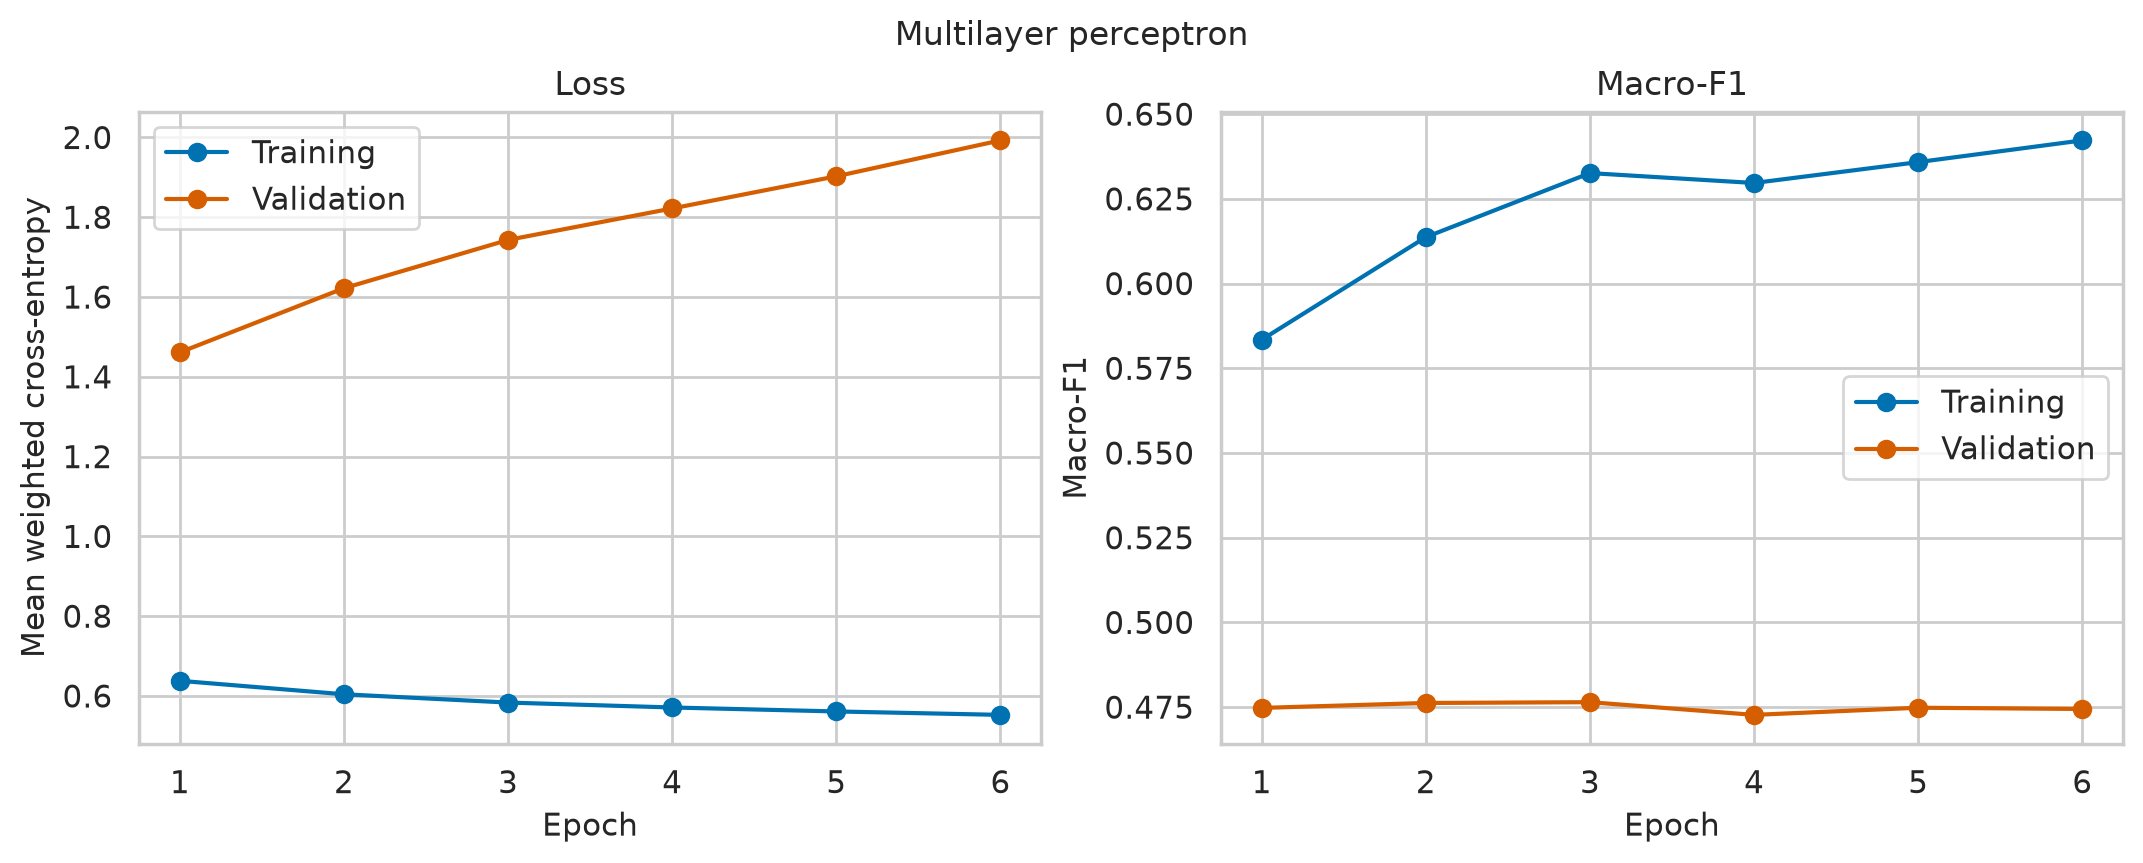

Scoring multilayer_perceptron on train...


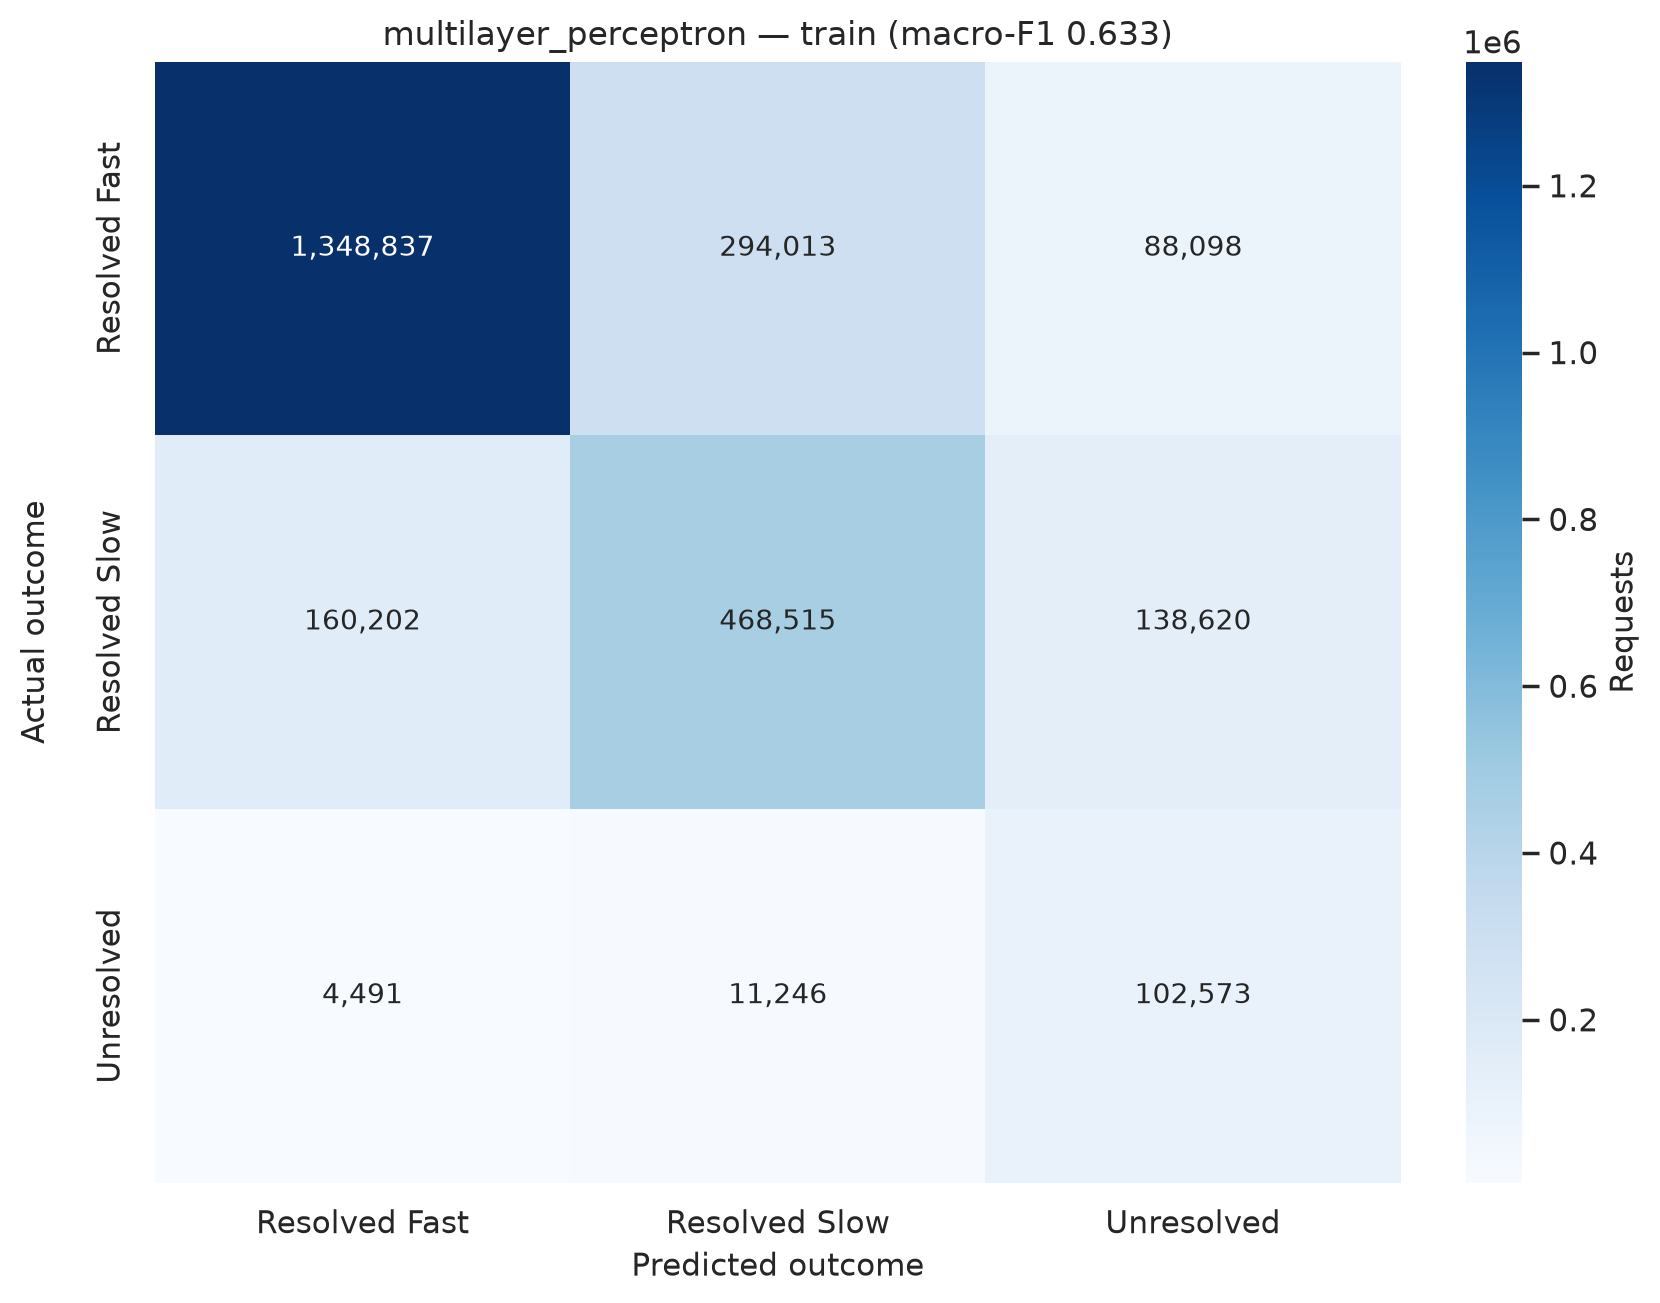

Scoring multilayer_perceptron on validation...


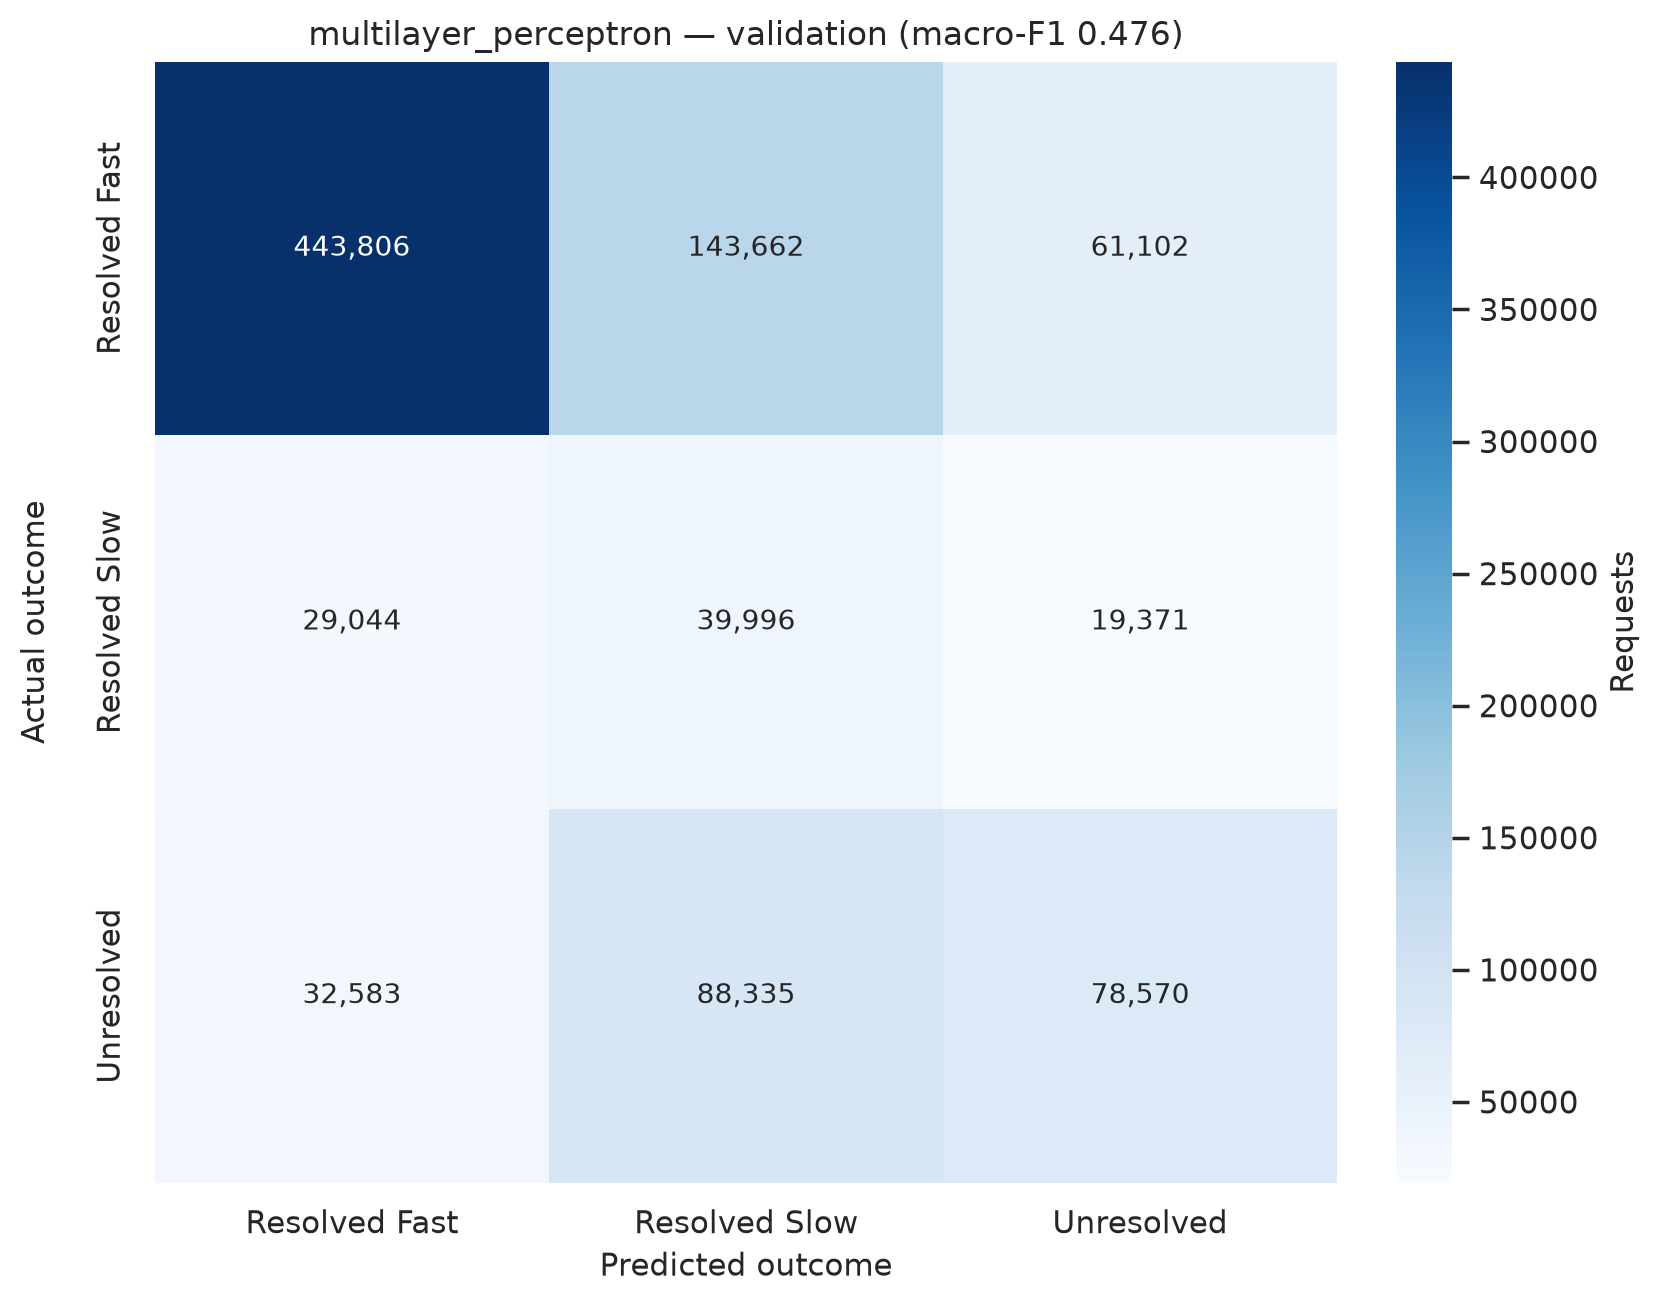

In [3]:
preprocessor = build_baseline_preprocessor()
preprocessor.fit(X_train)
X_train_encoded = preprocessor.transform(X_train)
X_validation_encoded = preprocessor.transform(X_validation)
print(f"MLP input columns: {X_train_encoded.shape[1]:,}")

mlp_result = train_feedforward(
    X_train_encoded,
    y_train,
    X_validation_encoded,
    y_validation,
    verbose=True,
)
print(f"Parameters: {mlp_result['n_parameters']:,}")
print(f"Epochs run: {mlp_result['epochs_ran']}")
print(f"Restored epoch: {mlp_result['best_epoch']}")
print(f"Stopped early: {mlp_result['stopped_early']}")
print(f"Fit seconds: {mlp_result['fit_seconds']:.1f}")
print("Class weights:", [round(weight, 3) for weight in mlp_result["class_weights"]])
print("Architecture, optimiser, learning rate, batch size, dropout, and weight decay:")
display(pd.Series(mlp_result["parameters"]))

_figure, mlp_curve_path = plot_learning_curves(
    mlp_result["history"],
    "Multilayer perceptron",
    "05_mlp_learning_curves.png",
)
display(Image(filename=str(mlp_curve_path)))
mlp_result["history"].to_csv(config.TABLES_DIR / "05_mlp_history.csv", index=False)


def score_neural(model_name, predict, approval, fit_seconds, pending=False):
    summaries = []
    per_class_frames = []
    for split_name, features, labels in (
        ("train", X_train_encoded, y_train),
        ("validation", X_validation_encoded, y_validation),
    ):
        print(f"Scoring {model_name} on {split_name}...", flush=True)
        if model_name == "multilayer_perceptron":
            predicted, probabilities, _loss = predict_feedforward(
                mlp_result["model"],
                features,
                class_indices(labels),
                batch_size=int(mlp_result["parameters"]["batch_size"]),
            )
        else:
            predicted, probabilities = predict
        summary, per_class = summarise_predictions(
            labels,
            predicted,
            probabilities,
            model=model_name,
            split=split_name,
            approval=approval,
            fit_seconds=fit_seconds,
        )
        scores = classification_scores(labels, predicted)
        prefix = "Pending approval: " if pending else ""
        title = f"{prefix}{model_name} — {split_name} (macro-F1 {scores['macro_f1']:.3f})"
        _figure, path = plot_confusion_matrix(
            scores["confusion_matrix"],
            list(config.TARGET_LABELS),
            title,
            f"05_confusion_{model_name}_{split_name}.png",
        )
        display(Image(filename=str(path)))
        summaries.append(summary)
        per_class_frames.append(per_class)
    return summaries, per_class_frames


mlp_summaries, mlp_classes = score_neural(
    "multilayer_perceptron",
    None,
    APPROVED_APPROVAL,
    mlp_result["fit_seconds"],
)
del X_train_encoded, X_validation_encoded


## 3. Categorical embedding network

Lecturer approval has been recorded for this network. No approval date was supplied, and the architecture was not changed. The saved outputs in this notebook are the original run and were not recomputed. The network gives each training category its own embedding. Index 0 is reserved for a category that was absent from the training vocabulary, and that vector is initialised at zero and is not updated. Missing values and rare training levels have their own trained indices. The weekend indicator is standardised with a scaler fit on the training rows.

The same optimiser, dropout, weight decay, batch size, class-weighted cross-entropy, and validation early stopping are used. The champion rule is the highest validation macro-F1 among approved models. This network's validation macro-F1 is below histogram gradient boosting, so it is not the champion. No locked-test score was produced for it. Re-running this notebook would refit both networks and rewrite results/tables/05_*.csv, so the status text was corrected without a rerun. Reproduce the saved checkpoint with `python -m src.embedding_experiment`.


Lecturer approval has been recorded for the existing embedding network. No approval date was supplied, and the architecture was not changed.


,column,distinct_training_levels,kept_levels,grouped_levels,missing_training_rows,embedding_rows,unseen_index,min_count
0,C3_Complaint_Type,998,372,626,0,374,0,200
1,Suburb,28394,1080,27314,0,1082,0,200
2,Ward,219,218,1,0,220,0,200
3,Sub_Council,32,23,9,164058,26,0,200
4,created_day_of_week,7,7,0,0,8,0,200
5,created_month,12,12,0,0,13,0,200


Training rows mapped to the unseen index: 0


embedding epoch 1: train_loss 0.7107, val_loss 1.3416, train_macro_f1 0.5511, val_macro_f1 0.4686


embedding epoch 2: train_loss 0.6665, val_loss 1.4055, train_macro_f1 0.5768, val_macro_f1 0.4783


...

embedding epoch 4: train_loss 0.6401, val_loss 1.4875, train_macro_f1 0.5858, val_macro_f1 0.4807


embedding epoch 5: train_loss 0.6337, val_loss 1.5342, train_macro_f1 0.5874, val_macro_f1 0.4788


embedding epoch 6: train_loss 0.6260, val_loss 1.6056, train_macro_f1 0.5970, val_macro_f1 0.4763


embedding epoch 7: train_loss 0.6212, val_loss 1.6584, train_macro_f1 0.6000, val_macro_f1 0.4760


Parameters: 34,035
Epochs run: 7
Restored epoch: 4
Stopped early: True
Fit seconds: 230.3
Lecturer approval has been recorded for the existing embedding network. No approval date was supplied, and the architecture was not changed.


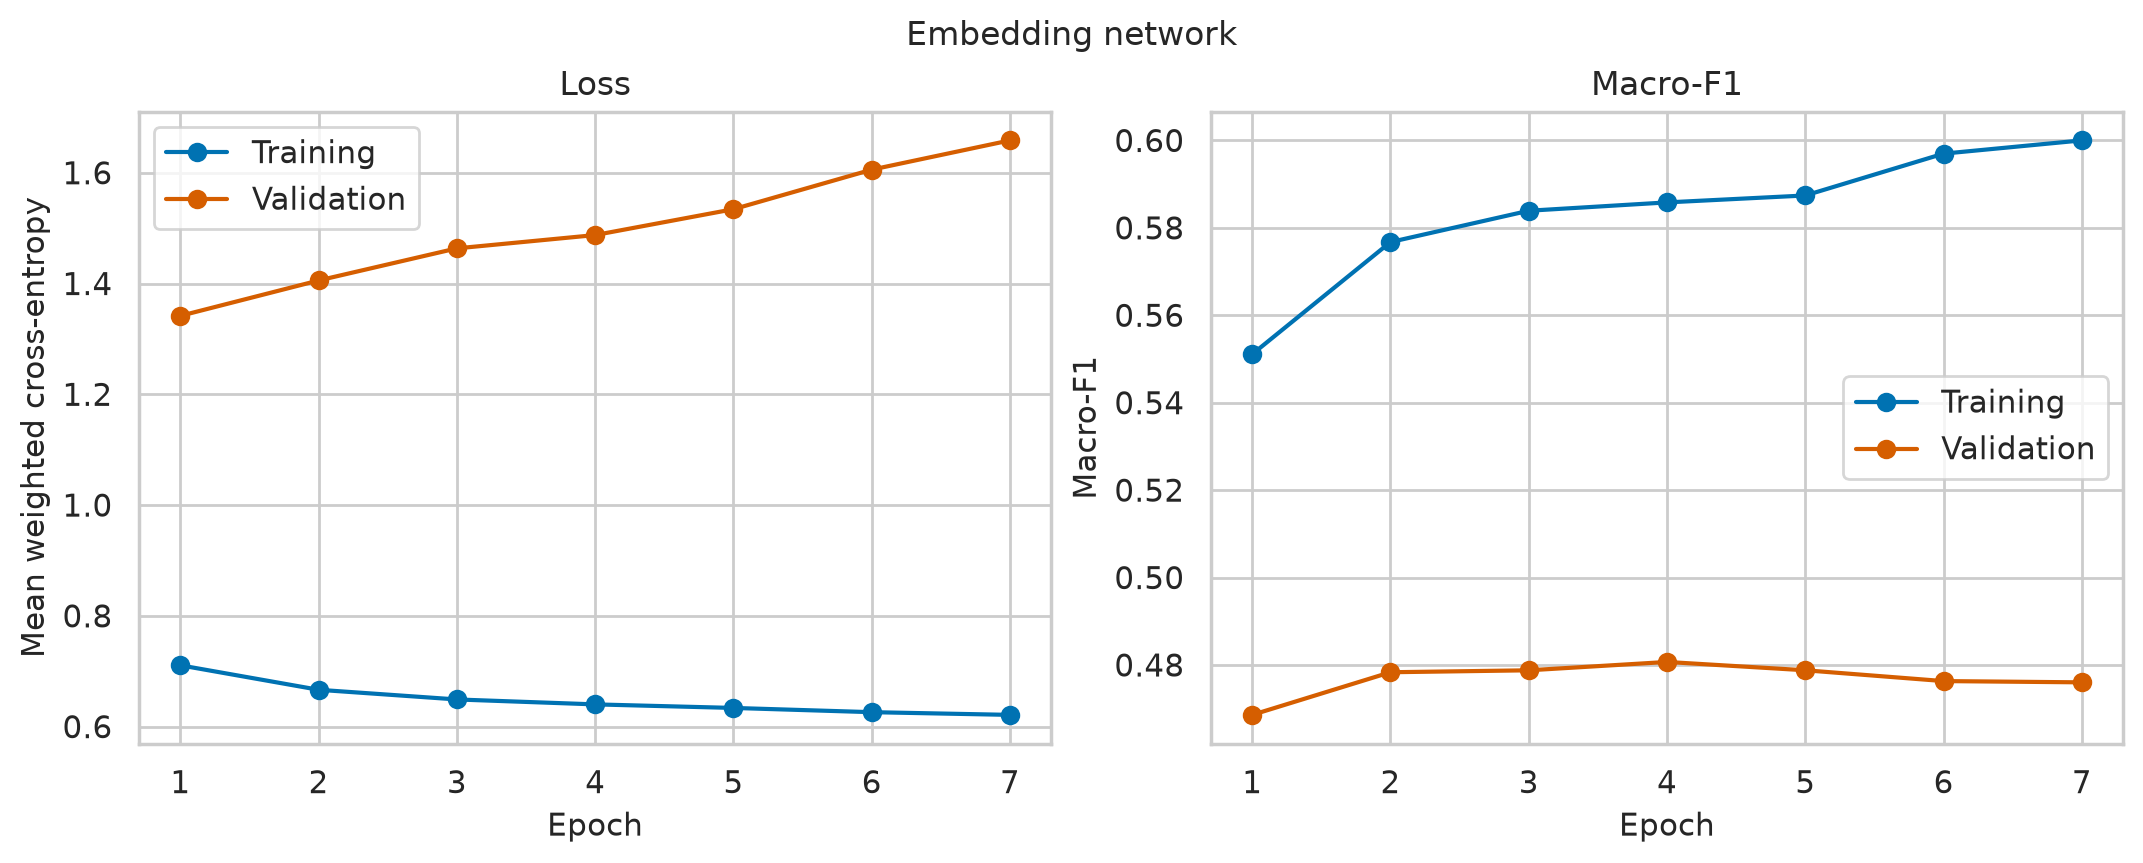

Scoring embedding_network on train...


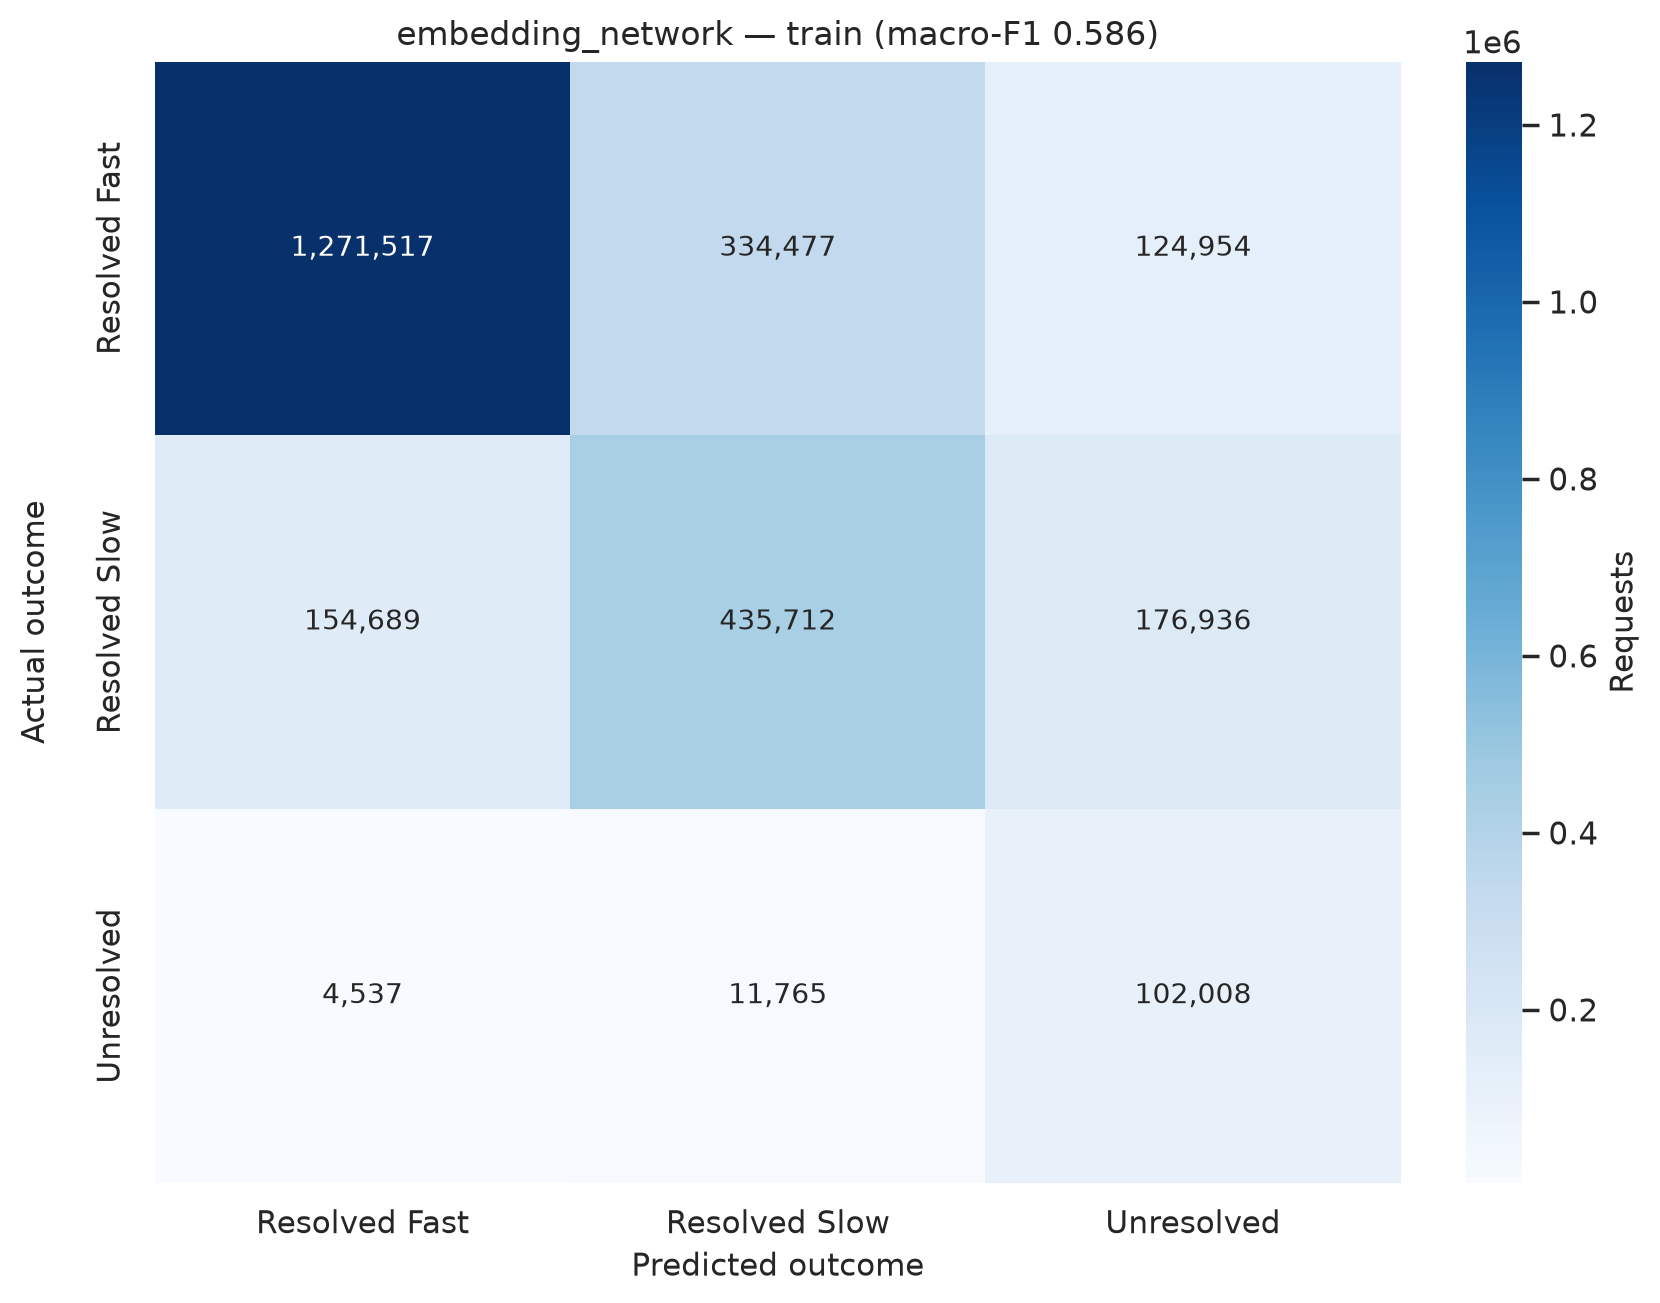

Scoring embedding_network on validation...


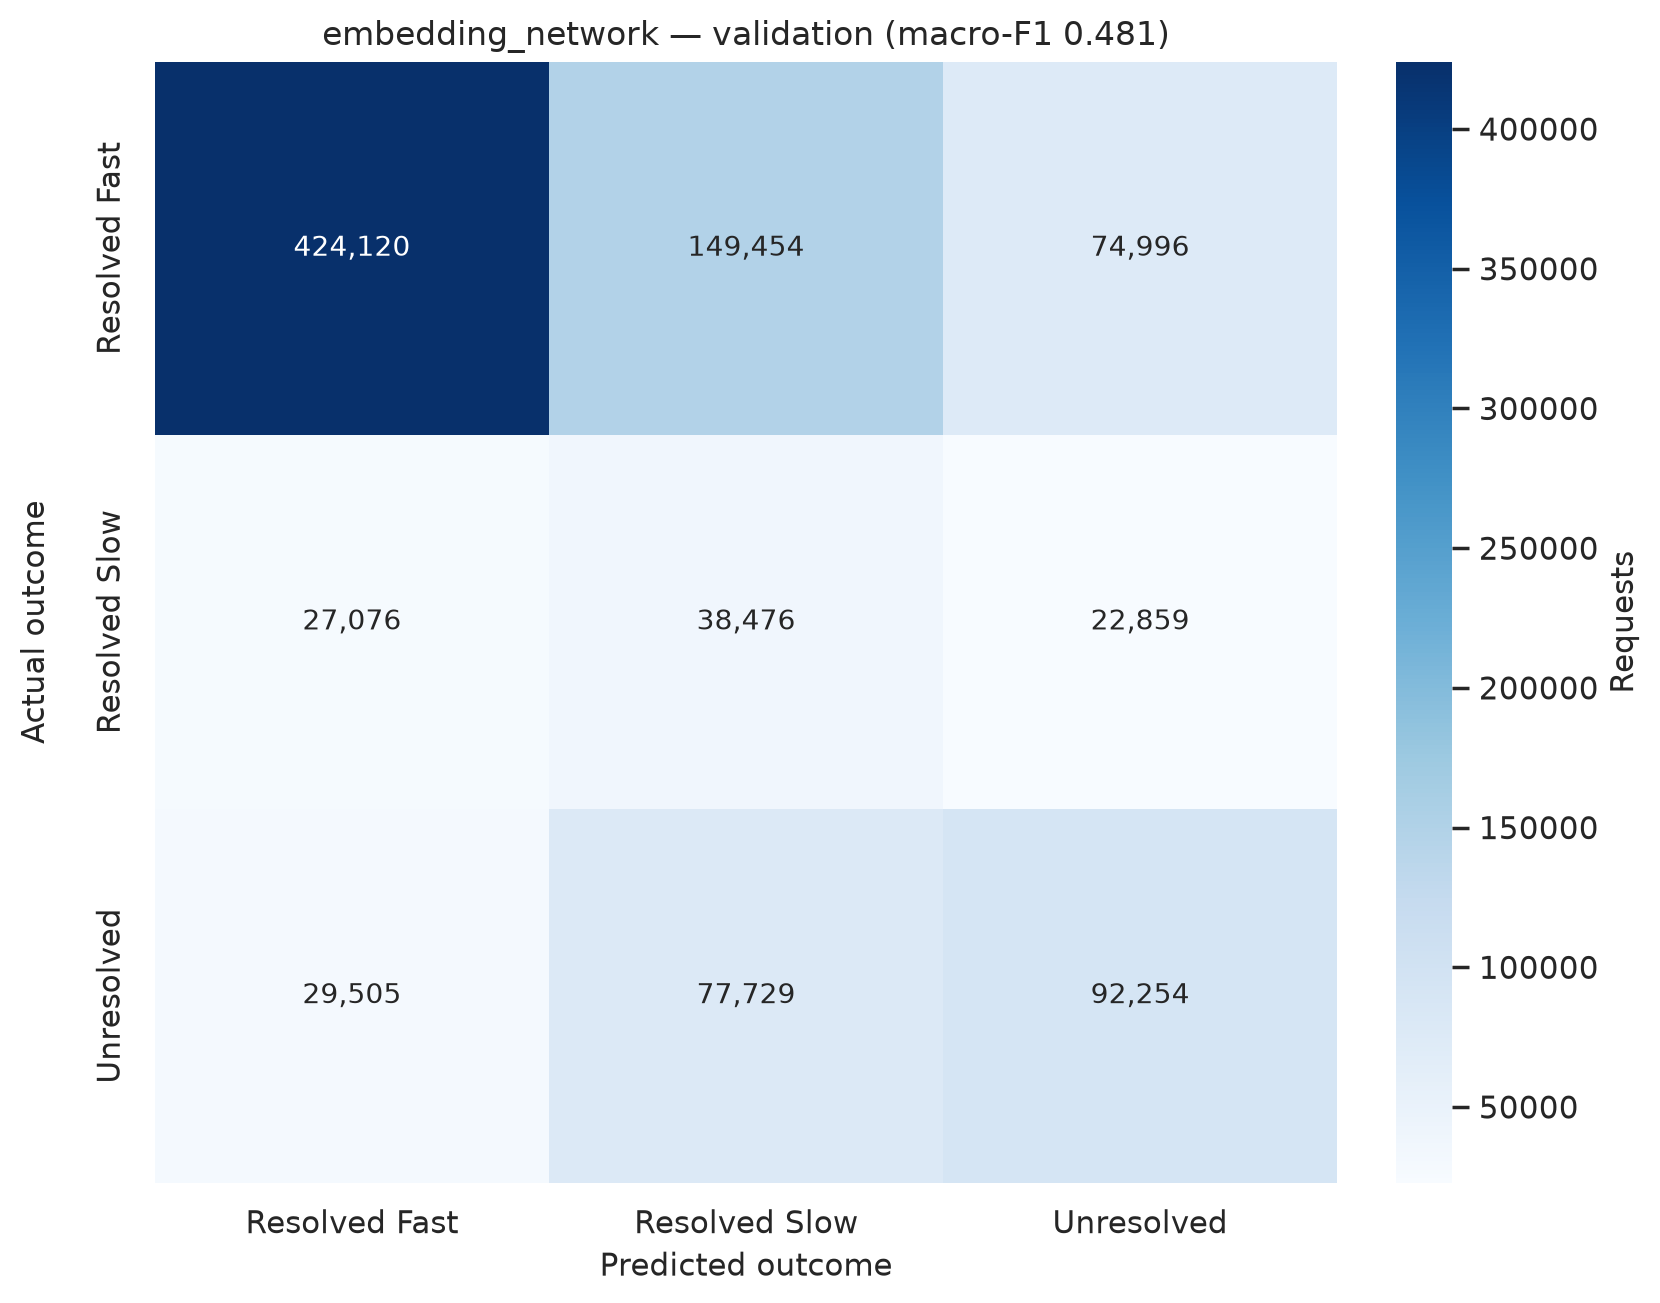

In [4]:
print(APPROVED_EMBEDDING_NOTE)
embedding_encoder = EmbeddingCategoryEncoder().fit(X_train)
display(embedding_encoder.level_summary())
train_embedded = embedding_encoder.transform(X_train)
validation_embedded = embedding_encoder.transform(X_validation)
training_unseen = int(np.sum(train_embedded["codes"] == 0))
print(f"Training rows mapped to the unseen index: {training_unseen}")
if training_unseen != 0:
    raise RuntimeError("Training rows must not use the reserved unseen index.")

embedding_result = train_embedding_network(
    train_embedded["codes"],
    train_embedded["numeric"],
    y_train,
    validation_embedded["codes"],
    validation_embedded["numeric"],
    y_validation,
    embedding_encoder.cardinalities_,
    verbose=True,
)
print(f"Parameters: {embedding_result['n_parameters']:,}")
print(f"Epochs run: {embedding_result['epochs_ran']}")
print(f"Restored epoch: {embedding_result['best_epoch']}")
print(f"Stopped early: {embedding_result['stopped_early']}")
print(f"Fit seconds: {embedding_result['fit_seconds']:.1f}")
print(embedding_result["approval_note"])

_figure, embedding_curve_path = plot_learning_curves(
    embedding_result["history"],
    "Embedding network",
    "05_embedding_learning_curves.png",
)
display(Image(filename=str(embedding_curve_path)))
embedding_result["history"].to_csv(config.TABLES_DIR / "05_embedding_history.csv", index=False)

embedding_summaries = []
embedding_classes = []
batch_size = int(embedding_result["parameters"]["batch_size"])
for split_name, embedded, labels in (
    ("train", train_embedded, y_train),
    ("validation", validation_embedded, y_validation),
):
    print(f"Scoring embedding_network on {split_name}...", flush=True)
    predicted, probabilities, _loss = predict_embedding(
        embedding_result["model"],
        embedded["codes"],
        embedded["numeric"],
        class_indices(labels),
        batch_size,
    )
    summary, per_class = summarise_predictions(
        labels,
        predicted,
        probabilities,
        model="embedding_network",
        split=split_name,
        approval=APPROVED_APPROVAL,
        fit_seconds=embedding_result["fit_seconds"],
    )
    scores = classification_scores(labels, predicted)
    _figure, path = plot_confusion_matrix(
        scores["confusion_matrix"],
        list(config.TARGET_LABELS),
        f"embedding_network — {split_name} (macro-F1 {scores['macro_f1']:.3f})",
        f"05_confusion_embedding_network_{split_name}.png",
    )
    display(Image(filename=str(path)))
    embedding_summaries.append(summary)
    embedding_classes.append(per_class)


## 4. Validation comparison and the provisional champion

The table brings the logistic regression, the gradient boosting model, the multilayer perceptron, and the embedding network together. Ranking uses validation macro-F1 among approved models. The embedding network is approved and does not win. Resolved Slow recall and Unresolved recall are reported beside that score. The locked test is not in the table.

Training macro-F1 is compared with validation macro-F1 on the full periods. A higher training score is the sign used here for overfitting. The 2025 class mix also differs from the 2023–2024 mix, so a gap is not only a capacity problem.
The approval label in the saved comparison output was corrected from `pending_lecturer_approval` to `approved` after lecturer approval was recorded. The scores in that output were not recomputed. The file `results/figures/05_embedding_learning_curves.png` still has the old title, Embedding network (pending lecturer approval). It is kept for traceability and is not the figure used by the final report. The corrected curve is `results/figures/10_embedding_learning_curves.png`, titled Approved embedding network. This cell still writes `05_embedding_learning_curves.png` when the notebook is run, and that rerun was not used to replace the saved figure.


,model,approval,accuracy,macro_f1,weighted_f1,recall_resolved_fast,recall_resolved_slow,recall_unresolved,macro_roc_auc,macro_average_precision,fit_seconds
0,hist_gradient_boosting,approved,0.591,0.482,0.640,0.646,0.416,0.492,0.739,0.506,17.734
1,embedding_network,approved,0.592,0.481,0.642,0.654,0.435,0.462,0.741,0.513,230.322
2,multilayer_perceptron,approved,0.601,0.476,0.647,0.684,0.452,0.394,0.739,0.508,339.634
3,logistic_regression,approved,0.578,0.460,0.630,0.659,0.460,0.367,0.729,0.496,223.251


Provisional champion: hist_gradient_boosting
Validation macro-F1: 0.482
Validation Resolved Slow recall: 0.416
Validation Unresolved recall: 0.492
Selection rule: highest validation macro-F1 among approved models.
The embedding network is approved and does not win on validation macro-F1. No locked-test score was produced. The locked test was not scored.


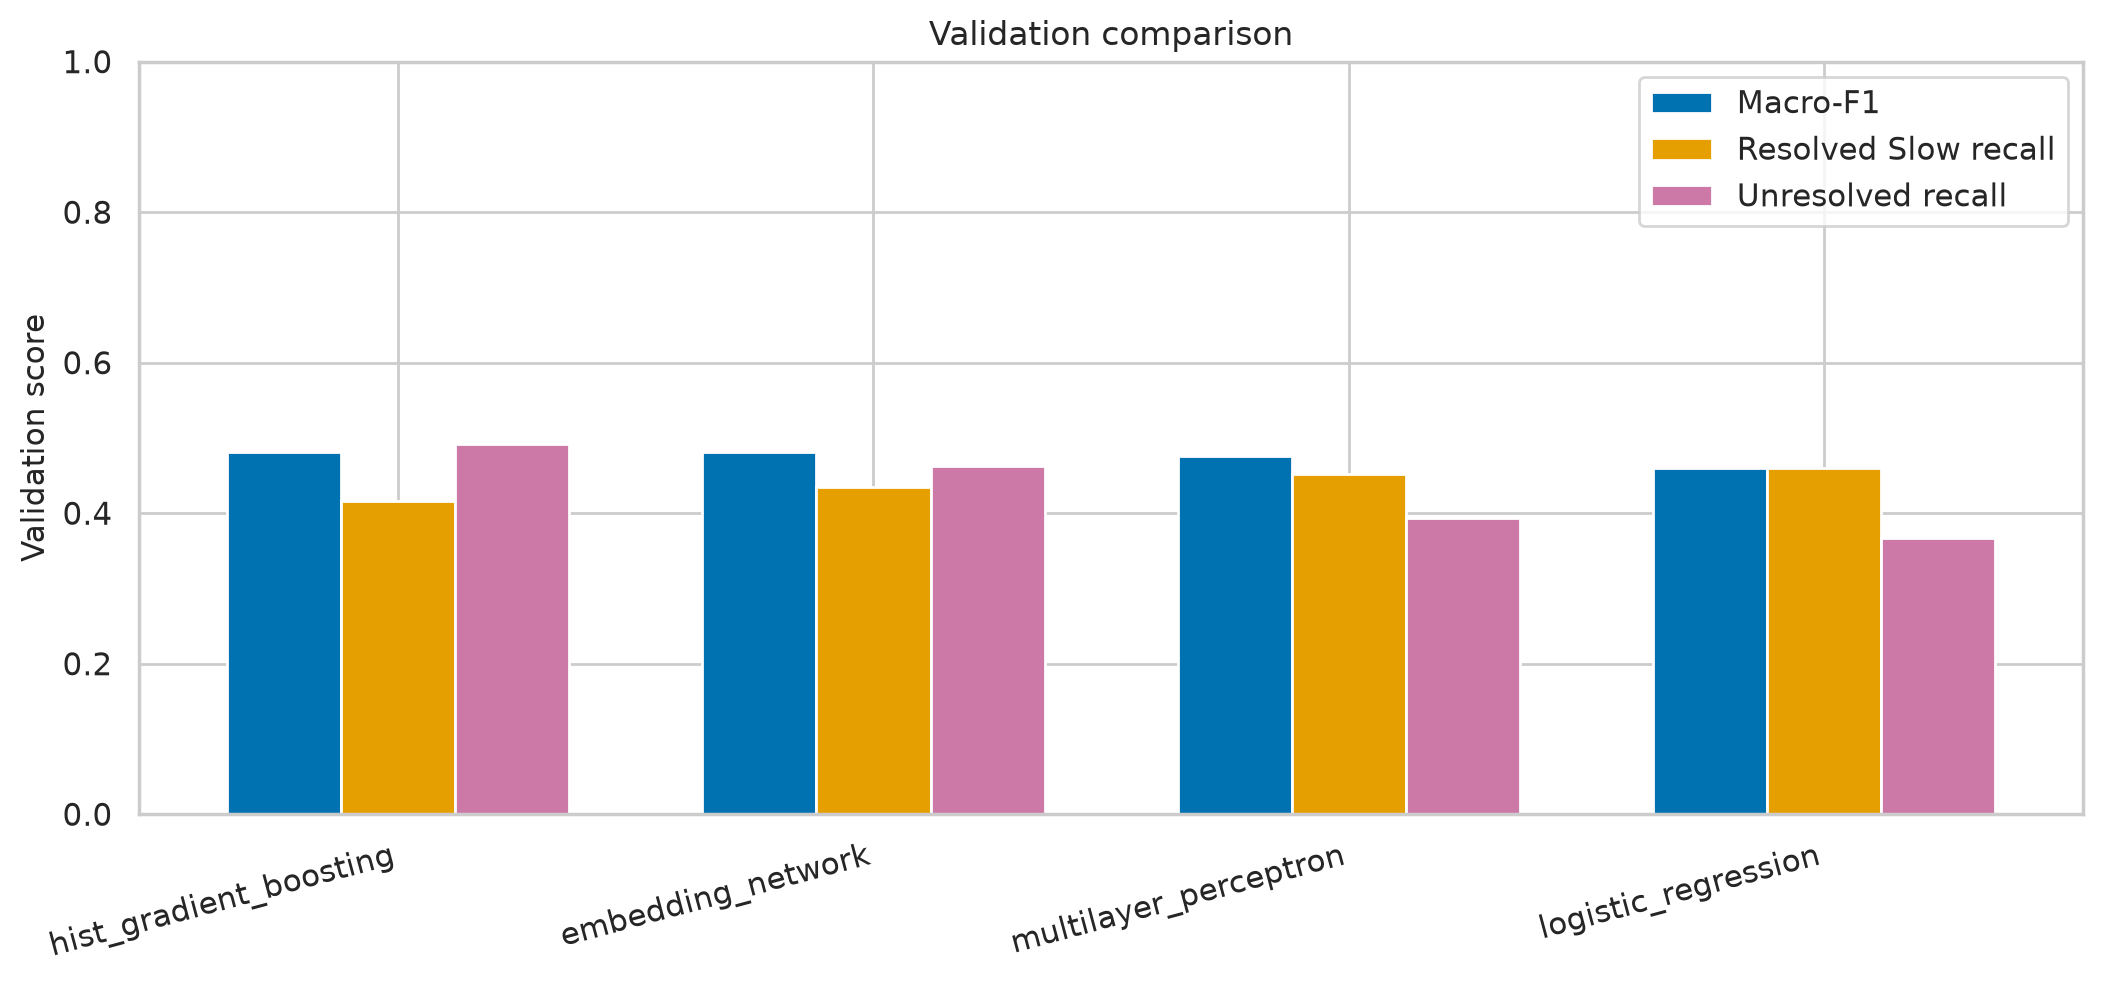

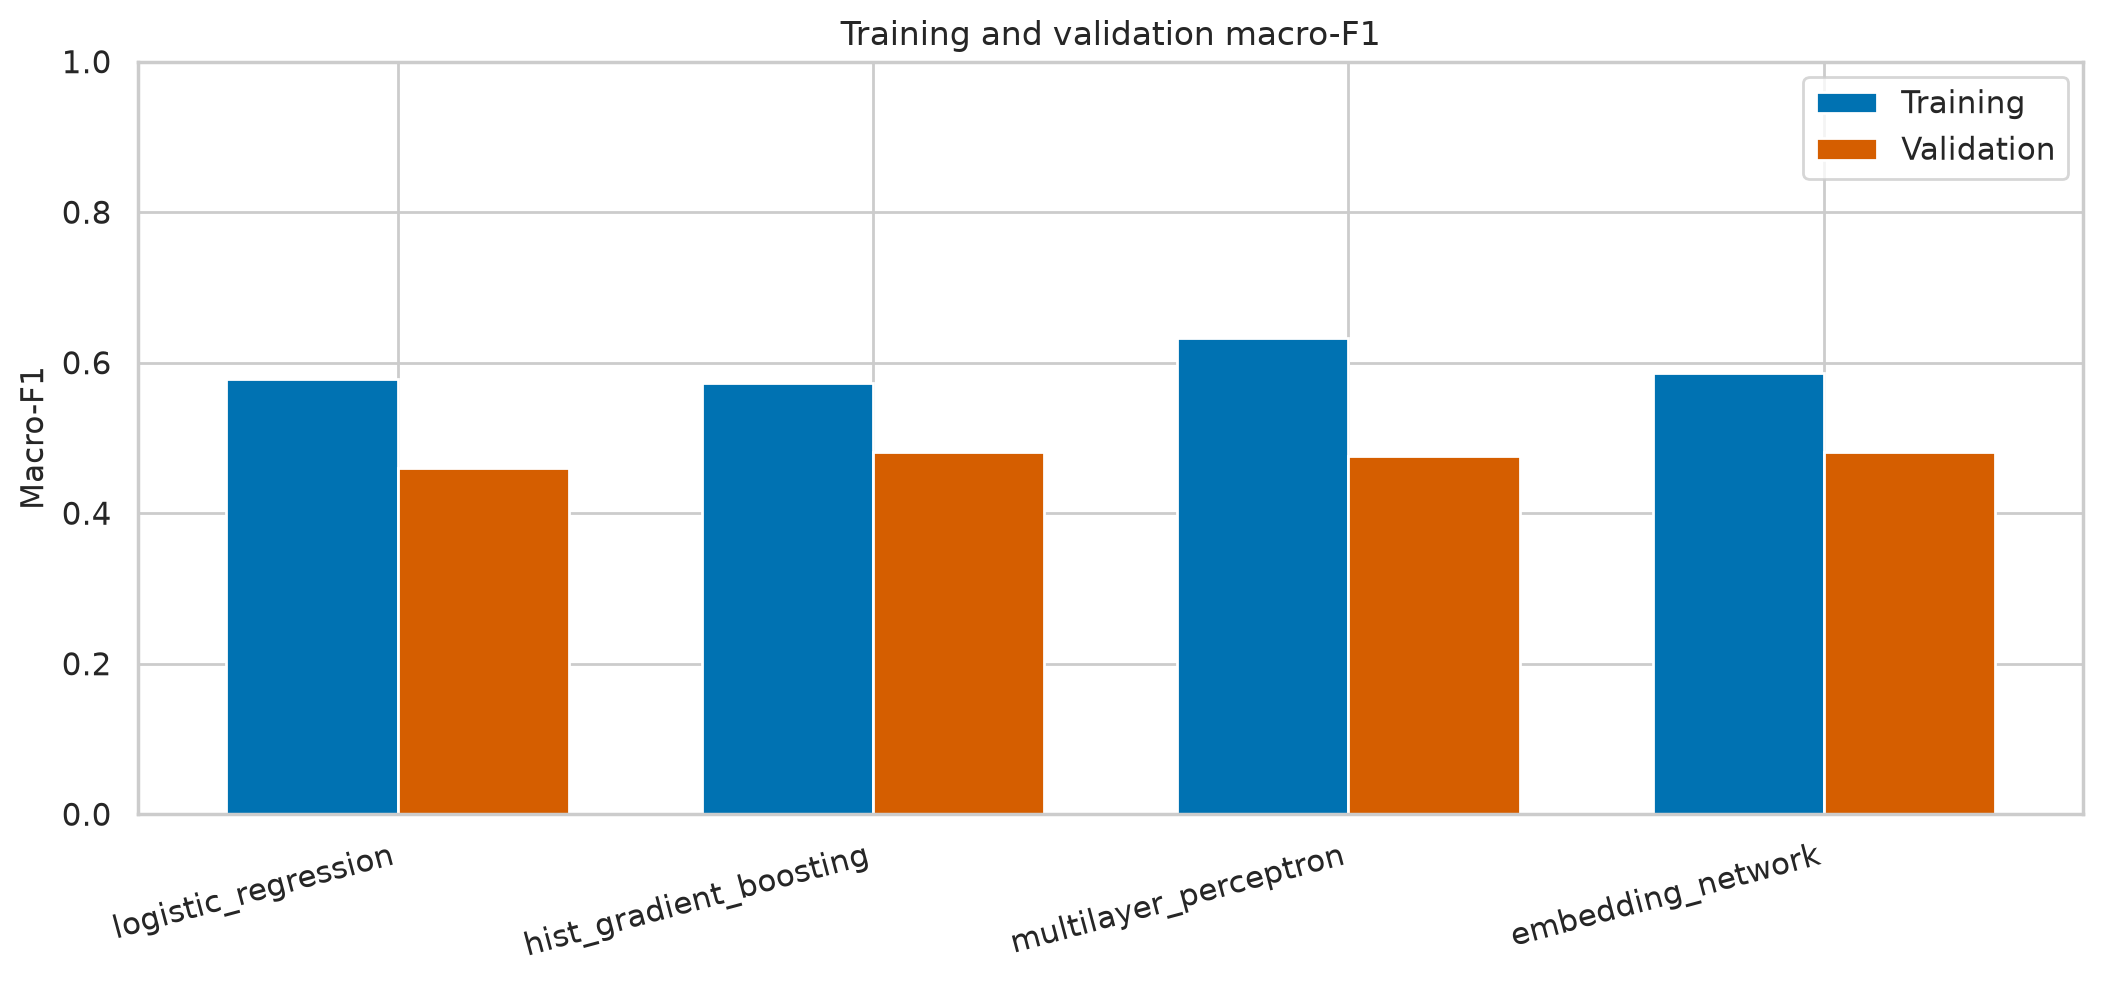

Wrote /workspace/evidence/reproducibility/notebooks/isolated/reports/phase5_models.md
# Phase 5 model experiments

Notebooks 04 and 05 fit the traditional models and the neural models on the same chronological partitions. The provisional champion is chosen from validation macro-F1. The locked test is not scored in this phase.

## Split

- Train: 2023-01-01 to 2024-12-31, 2,616,595 labelled requests (66.2% Resolved Fast, 29.3% Resolved Slow, 4.5% Unresolved).
- Validation: 2025-02-01 to 2025-12-31, 936,469 labelled requests (69.3% Resolved Fast, 9.4% Resolved Slow, 21.3% Unresolved).
- Locked test, not scored: 2026-01-01 to 2026-04-30, 422,033 labelled requests (68.0% Resolved Fast, 15.5% Resolved Slow, 16.4% Unresolved).

The split dates are the Phase 4 dates. They were not moved to improve a model score.

## Encoding

The one-hot training matrix has 2,616,595 rows and 1,718 columns, with 18,316,165 stored values. A dense float32 copy would be 16.7 GiB. The sparse matrix is practical f

In [5]:
traditional_summary = pd.read_csv(traditional_path)
traditional_per_class = pd.read_csv(traditional_class_path)
neural_summary = pd.concat(mlp_summaries + embedding_summaries, ignore_index=True)
neural_per_class = pd.concat(mlp_classes + embedding_classes, ignore_index=True)
metrics = pd.concat([traditional_summary, neural_summary], ignore_index=True)
per_class = pd.concat([traditional_per_class, neural_per_class], ignore_index=True)
comparison = validation_comparison(metrics)
chosen = provisional_champion(metrics)

display(comparison.round(3))
print(f"Provisional champion: {chosen['model']}")
print(f"Validation macro-F1: {float(chosen['macro_f1']):.3f}")
print(f"Validation Resolved Slow recall: {float(chosen['recall_resolved_slow']):.3f}")
print(f"Validation Unresolved recall: {float(chosen['recall_unresolved']):.3f}")
print("Selection rule: highest validation macro-F1 among approved models.")
print("The embedding network is approved and does not win on validation macro-F1. No locked-test score was produced. The locked test was not scored.")

_figure, comparison_path = plot_validation_comparison(comparison)
_figure, gap_path = plot_train_validation_macro_f1(metrics)
display(Image(filename=str(comparison_path)))
display(Image(filename=str(gap_path)))

metrics.to_csv(config.TABLES_DIR / "05_split_metrics.csv", index=False)
per_class.to_csv(config.TABLES_DIR / "05_per_class.csv", index=False)
comparison.to_csv(config.TABLES_DIR / "05_model_comparison.csv", index=False)

traditional_run = json.loads(traditional_run_path.read_text(encoding="utf-8"))
run_notes = {
    "logistic_regression": traditional_run["logistic_regression"],
    "hist_gradient_boosting": traditional_run["hist_gradient_boosting"],
    "multilayer_perceptron": {
        "hidden_sizes": list(mlp_result["parameters"]["hidden_sizes"]),
        "dropout": float(mlp_result["parameters"]["dropout"]),
        "learning_rate": float(mlp_result["parameters"]["learning_rate"]),
        "weight_decay": float(mlp_result["parameters"]["weight_decay"]),
        "batch_size": int(mlp_result["parameters"]["batch_size"]),
        "n_parameters": int(mlp_result["n_parameters"]),
        "n_features": int(mlp_result["n_features"]),
        "epochs_ran": int(mlp_result["epochs_ran"]),
        "best_epoch": int(mlp_result["best_epoch"]),
        "stopped_early": bool(mlp_result["stopped_early"]),
        "fit_seconds": float(mlp_result["fit_seconds"]),
    },
    "embedding_network": {
        "embedding_dim": int(embedding_result["parameters"]["embedding_dim"]),
        "hidden_size": int(embedding_result["parameters"]["hidden_size"]),
        "dropout": float(embedding_result["parameters"]["dropout"]),
        "learning_rate": float(embedding_result["parameters"]["learning_rate"]),
        "weight_decay": float(embedding_result["parameters"]["weight_decay"]),
        "batch_size": int(embedding_result["parameters"]["batch_size"]),
        "epochs_ran": int(embedding_result["epochs_ran"]),
        "best_epoch": int(embedding_result["best_epoch"]),
        "fit_seconds": float(embedding_result["fit_seconds"]),
        "approval": APPROVED_APPROVAL,
    },
}
def _validation_loss_rose(history):
    return bool(
        history["validation_loss"].iloc[-1] > history["validation_loss"].iloc[0]
        and history["train_loss"].iloc[-1] < history["train_loss"].iloc[0]
    )
run_notes["neural_loss_curves"] = {
    "multilayer_perceptron": _validation_loss_rose(mlp_result["history"]),
    "embedding_network": _validation_loss_rose(embedding_result["history"]),
}
experiment = base_experiment_config()
experiment["measured"] = run_notes
experiment["provisional_champion"] = {
    "model": str(chosen["model"]),
    "validation_macro_f1": float(chosen["macro_f1"]),
    "recall_resolved_slow": float(chosen["recall_resolved_slow"]),
    "recall_unresolved": float(chosen["recall_unresolved"]),
    "locked_test_used": False,
}
save_json(experiment, config.TABLES_DIR / "05_experiment_config.json")

tree_levels = pd.read_csv(config.TABLES_DIR / "05_tree_category_levels.csv")
report = render_phase5_report(
    split_summary,
    traditional_run["one_hot"],
    tree_levels,
    metrics,
    run_notes,
)
report_path = config.REPORTS_DIR / "phase5_models.md"
report_path.write_text(report, encoding="utf-8")
print(f"Wrote {report_path}")
print(report)
